# 05 – Kiểm định dHash bằng biến đổi tổng hợp và đường ROC (tự động, không xem tay)

**Bản cho dữ liệu export "Fit with border":** ảnh được bỏ viền đồng màu trước khi băm (hàm `cat_vien`, giống hệt notebook 03).
Chạy notebook này TRƯỚC notebook 03 để xác nhận ngưỡng τ = 10 vẫn cho TPR cao và FPR ≈ 0 trên dữ liệu mới.

**Mục đích:** đo định lượng khả năng của dHash (cách tính giống hệt notebook 03) trong việc
(a) **nhận ra** một ảnh sau các biến đổi không làm đổi nội dung (tỉ lệ dương đúng – TPR), và
(b) **không nhầm** hai cảnh khác nhau là giống nhau (tỉ lệ dương giả – FPR), ở từng ngưỡng khoảng cách Hamming τ.

**Phương pháp theo:** Vallez và cộng sự, *Needle In A Haystack, Fast: Benchmarking Image Perceptual Similarity
Metrics At Scale* (arXiv:2206.00282, 2022): áp các nhiễu loạn nhóm "noise-like", "geometric", "enhancement" lên một tập
ảnh "thí nghiệm" để tạo cặp dương; dùng một tập "đối chứng" để tạo cặp âm; báo cáo đường ROC, AUC, recall và FPR;
bài này dùng hash 64 bit và mốc FPR khoảng 0,5% khi so sánh. Zauner và cộng sự (Rihamark, SPIE 7880, 2011)
cũng đánh giá hàm băm ảnh theo độ bền với các phép biến đổi.

**Áp dụng cho bộ dữ liệu này:**
- **Cặp dương:** `N_EXP` ảnh chọn ngẫu nhiên, mỗi ảnh áp các biến đổi trong bảng `TRANSFORMS` (chỉ những biến đổi có thể
  xảy ra giữa hai ảnh cùng cảnh của camera hành trình: nén, nhiễu, mờ, đổi sáng/tương phản/màu, đổi kích thước, cắt nhẹ,
  dịch khung, chồng chữ kiểu dấu thời gian). **Không** dùng lật ngang hay xoay mạnh (lật đổi nghĩa biển trái/phải).
- **Cặp âm (đối chứng), không dựa vào dHash:** cặp ảnh ngẫu nhiên mà **hai tập lớp biển không có lớp chung**. Hai ảnh
  không có biển nào chung thì không thể là cùng một cảnh (giả định nhãn đầy đủ), nên đây là cặp âm xác định độc lập với
  chính dHash đang được kiểm định.

**Giới hạn (phải nêu trong bài):** biến đổi tổng hợp không mô phỏng hết sự khác nhau giữa hai khung hình liền nhau của
video (vật thể chuyển động). Vì vậy kết quả này dùng **cùng với** phép kiểm tra hiệu ứng ghi nhớ (F1 theo khoảng cách
tới ảnh train gần nhất), không thay thế nó.

**Đầu vào:** `MyDrive/VNTrafficSign/output_cleaneddata_fit/cleaned_data.zip` (notebook 01 trên bản export "Fit with border").
**Đầu ra:** `MyDrive/VNTrafficSign/output_dhash_roc/` (bảng, hình, `summary.json`). Notebook không sửa dữ liệu.

In [3]:
import json
import os
import shutil
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from PIL import Image, ImageDraw, ImageEnhance, ImageFilter, ImageOps

try:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_ROOT = Path('/content/drive/MyDrive/VNTrafficSign')
    LOCAL_ROOT = Path('/content')
except ImportError:  # chạy ngoài Colab (kiểm thử)
    DRIVE_ROOT = Path(os.environ.get('VNTS_DRIVE_ROOT', './VNTrafficSign'))
    LOCAL_ROOT = Path(os.environ.get('VNTS_LOCAL_ROOT', './local'))
try:
    display
except NameError:
    display = print

CLEAN_ZIP = DRIVE_ROOT / 'output_cleaneddata_fit' / 'cleaned_data.zip'   # notebook 01 trên bản export "Fit with border"
OUT_DIR = DRIVE_ROOT / 'output_dhash_roc_fit'
TAB_DIR, FIG_DIR = OUT_DIR / 'tables', OUT_DIR / 'figures'
SRC_DIR = LOCAL_ROOT / 'roc_src'

SEED = 42
N_EXP = 300               # số ảnh "thí nghiệm" tạo cặp dương
N_NEG = 20000             # số cặp âm (hai ảnh không có lớp biển chung)
TAU_MAX = 20              # quét τ = 0..TAU_MAX
TAU_CHON = 10             # ngưỡng nhóm đã chọn (để báo cáo riêng)
FPR_MOC = 0.005           # mốc FPR 0,5% (Vallez và cộng sự, 2022)
IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
for d in (TAB_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
assert CLEAN_ZIP.exists(), f'Không tìm thấy {CLEAN_ZIP}'
rng = np.random.default_rng(SEED)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Giải nén, đọc nhãn, tính dHash cho mọi ảnh (giống hệt notebook 03)

In [4]:
if SRC_DIR.exists():
    shutil.rmtree(SRC_DIR)
SRC_DIR.mkdir(parents=True)
with zipfile.ZipFile(CLEAN_ZIP) as zf:
    zf.extractall(SRC_DIR)
imgs = sorted(p for p in SRC_DIR.rglob('*') if p.parent.name == 'images' and p.suffix.lower() in IMG_EXTS)
print('Số ảnh:', len(imgs))


def classes_of(img_path):
    lp = img_path.parent.parent / 'labels' / (img_path.stem + '.txt')
    out = set()
    if lp.exists():
        for line in lp.read_text(encoding='utf-8').splitlines():
            v = line.split()
            if len(v) >= 5:
                out.add(int(float(v[0])))
    return frozenset(out)


def dhash_img(im, size=8):
    """Đúng cách tính của notebook 03: ảnh xám, LANCZOS về 9×8, so sánh hai điểm ảnh kề nhau theo hàng."""
    g = np.asarray(im.convert('L').resize((size + 1, size), Image.LANCZOS), dtype=np.int16)
    bits = (g[:, 1:] > g[:, :-1]).ravel()
    return int(''.join('1' if b else '0' for b in bits), 2)



# ---- Bỏ viền "Fit with border" của Roboflow trước khi tính dHash ----
# Viền là các hàng/cột đồng màu (đen hoặc trắng) ở hai mép đối diện. Viền giống hệt nhau giữa các ảnh có cùng tỉ lệ khung
# nên nếu băm cả viền, hai ảnh khác nhau sẽ trông gần nhau hơn. Chỉ cắt khi: viền nằm trên ĐÚNG MỘT trục (trên–dưới hoặc
# trái–phải) và có ở CẢ HAI mép. Roboflow đặt ảnh ở giữa khung nên viền thật = mép nhỏ hơn; nếu hai mép lệch nhau quá
# VIEN_LECH điểm ảnh (ví dụ ảnh đêm có trời tối sát viền), chỉ cắt theo mép nhỏ hơn ở cả hai phía. Viền chỉ ở một mép hoặc
# ở cả hai trục: không cắt. Mọi quyết định cắt được ghi vào bảng để kiểm tra.
VIEN_TOL = 24       # sai khác tối đa so với màu viền (bù nhiễu nén JPEG)
VIEN_FRAC = 0.99    # tỉ lệ điểm ảnh tối thiểu trong một hàng/cột phải gần màu viền
VIEN_MIN = 2        # viền tối thiểu (điểm ảnh) ở mỗi mép
VIEN_LECH = 3       # độ lệch tối đa giữa hai mép đối diện


def _so_hang_vien(a, color, axis, from_end):
    """Số hàng (axis=0) hoặc cột (axis=1) liên tiếp từ mép là viền màu `color`."""
    ok = (np.abs(a - color).max(-1) <= VIEN_TOL)                  # điểm ảnh gần màu viền
    frac = ok.mean(axis=1 - axis)                                   # theo từng hàng (axis=0) / cột (axis=1)
    frac = frac[::-1] if from_end else frac
    bad = np.nonzero(frac < VIEN_FRAC)[0]
    return int(bad[0]) if len(bad) else len(frac)


def cat_vien(im):
    """Trả về (ảnh đã bỏ viền, thông tin). Không cắt nếu không chắc là viền."""
    a = np.asarray(im.convert('RGB'), dtype=np.int16)
    H, W = a.shape[:2]
    best = {'vien': 'khong', 'mau': '', 'tren': 0, 'duoi': 0, 'trai': 0, 'phai': 0}
    for name, color in (('den', 0), ('trang', 255)):
        t, b = _so_hang_vien(a, color, 0, False), _so_hang_vien(a, color, 0, True)
        l, r = _so_hang_vien(a, color, 1, False), _so_hang_vien(a, color, 1, True)
        doc = t >= VIEN_MIN and b >= VIEN_MIN and t + b < H
        ngang = l >= VIEN_MIN and r >= VIEN_MIN and l + r < W
        if doc and not ngang:
            # Ảnh được đặt giữa → viền thật = mép nhỏ hơn; phần tối dư ở mép kia (ví dụ trời đêm) là nội dung, giữ lại.
            m = min(t, b)
            kieu = 'tren-duoi' if abs(t - b) <= VIEN_LECH else 'tren-duoi (lech, cat theo mep nho)'
            return im.crop((0, m, W, H - m)), {'vien': kieu, 'mau': name, 'tren': t, 'duoi': b, 'trai': 0, 'phai': 0}
        if ngang and not doc:
            m = min(l, r)
            kieu = 'trai-phai' if abs(l - r) <= VIEN_LECH else 'trai-phai (lech, cat theo mep nho)'
            return im.crop((m, 0, W - m, H)), {'vien': kieu, 'mau': name, 'tren': 0, 'duoi': 0, 'trai': l, 'phai': r}
        if max(t, b, l, r) >= VIEN_MIN and best['vien'] == 'khong':
            best = {'vien': 'mot-phia/khong-ro', 'mau': name, 'tren': t, 'duoi': b, 'trai': l, 'phai': r}
    return im, best


def load(p):
    """Ảnh đã xoay EXIF và BỎ VIỀN (giống hệt notebook 03); mọi biến đổi tạo cặp dương áp lên phần ảnh thật."""
    with Image.open(p) as im:
        return cat_vien(ImageOps.exif_transpose(im).convert('RGB'))[0]


hashes = np.array([dhash_img(load(p)) for p in imgs], dtype=np.uint64)
cls = [classes_of(p) for p in imgs]
ham = lambda a, b: bin(int(a) ^ int(b)).count('1')
print('Đã tính dHash cho', len(hashes), 'ảnh')

Số ảnh: 14509
Đã tính dHash cho 14509 ảnh


## 2. Các phép biến đổi tạo cặp dương

Ba nhóm theo Vallez và cộng sự (2022): **nhiễu** (noise-like), **hình học** (geometric), **tăng cường** (enhancement).
Mỗi phép có vài mức độ; tên phép ghi kèm mức.

In [5]:
def jpeg(q):
    def f(im):
        import io
        b = io.BytesIO(); im.save(b, 'JPEG', quality=q); b.seek(0)
        return Image.open(b).convert('RGB')
    return f


def gauss_noise(sigma):
    def f(im):
        a = np.asarray(im).astype(np.float32) + np.random.default_rng(0).normal(0, sigma, (im.height, im.width, 3))
        return Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))
    return f


def crop_rescale(frac):           # cắt bỏ frac ở mỗi cạnh (cắt giữa) rồi đưa về kích thước cũ
    def f(im):
        W, H = im.size; dx, dy = int(W * frac / 2), int(H * frac / 2)
        return im.crop((dx, dy, W - dx, H - dy)).resize((W, H), Image.LANCZOS)
    return f


def shift(frac):                  # dịch khung ngang frac (mô phỏng camera dịch chuyển nhẹ)
    def f(im):
        W, H = im.size; dx = int(W * frac)
        return im.crop((dx, 0, W, H)).resize((W, H), Image.LANCZOS)
    return f


def scale(s):                     # thu nhỏ (giữ tỉ lệ)
    return lambda im: im.resize((max(1, int(im.width * s)), max(1, int(im.height * s))), Image.LANCZOS)


def text_overlay(im):             # chồng dải chữ kiểu dấu thời gian camera hành trình
    im = im.copy(); d = ImageDraw.Draw(im); W, H = im.size
    d.rectangle([0, int(H * 0.93), W, H], fill=(0, 0, 0))
    d.text((int(W * 0.02), int(H * 0.94)), '2025-07-12 17:52:51   42km/h', fill=(255, 255, 255))
    return im


TRANSFORMS = {
    # nhiễu
    'nhieu: JPEG q90': jpeg(90), 'nhieu: JPEG q70': jpeg(70), 'nhieu: JPEG q50': jpeg(50), 'nhieu: JPEG q30': jpeg(30),
    'nhieu: Gauss sigma5': gauss_noise(5), 'nhieu: Gauss sigma10': gauss_noise(10), 'nhieu: Gauss sigma20': gauss_noise(20),
    'nhieu: mo r1': lambda im: im.filter(ImageFilter.GaussianBlur(1)),
    'nhieu: mo r2': lambda im: im.filter(ImageFilter.GaussianBlur(2)),
    'nhieu: loc trung vi 3': lambda im: im.filter(ImageFilter.MedianFilter(3)),
    # hình học
    'hinh hoc: thu nho 0.5': scale(0.5), 'hinh hoc: thu nho 0.25': scale(0.25),
    'hinh hoc: cat 5%': crop_rescale(0.05), 'hinh hoc: cat 10%': crop_rescale(0.10), 'hinh hoc: cat 20%': crop_rescale(0.20),
    'hinh hoc: dich 2%': shift(0.02), 'hinh hoc: dich 5%': shift(0.05), 'hinh hoc: dich 10%': shift(0.10),
    'hinh hoc: chong chu': text_overlay,
    # tăng cường
    'tang cuong: sang x0.7': lambda im: ImageEnhance.Brightness(im).enhance(0.7),
    'tang cuong: sang x1.3': lambda im: ImageEnhance.Brightness(im).enhance(1.3),
    'tang cuong: tuong phan x0.7': lambda im: ImageEnhance.Contrast(im).enhance(0.7),
    'tang cuong: tuong phan x1.3': lambda im: ImageEnhance.Contrast(im).enhance(1.3),
    'tang cuong: mau x0.5': lambda im: ImageEnhance.Color(im).enhance(0.5),
    'tang cuong: mau x1.5': lambda im: ImageEnhance.Color(im).enhance(1.5),
    'tang cuong: net x2': lambda im: ImageEnhance.Sharpness(im).enhance(2.0),
}
print(len(TRANSFORMS), 'phép biến đổi')

26 phép biến đổi


## 3. Tạo cặp dương (ảnh gốc ↔ ảnh đã biến đổi) và cặp âm (hai ảnh không có lớp biển chung)

In [6]:
exp_idx = rng.choice(len(imgs), size=min(N_EXP, len(imgs)), replace=False)
pos = []
for i in exp_idx:
    im = load(imgs[i])
    for name, f in TRANSFORMS.items():
        pos.append({'anh': imgs[i].name, 'bien_doi': name, 'nhom': name.split(':')[0],
                    'd': ham(hashes[i], dhash_img(f(im)))})
pos = pd.DataFrame(pos)

neg, tries = [], 0
n = len(imgs)
while len(neg) < N_NEG and tries < N_NEG * 50:
    a, b = rng.integers(0, n, 2); tries += 1
    if a == b or not cls[a] or not cls[b] or (cls[a] & cls[b]):
        continue
    neg.append({'anh_a': imgs[a].name, 'anh_b': imgs[b].name, 'd': ham(hashes[a], hashes[b])})
neg = pd.DataFrame(neg)
pos.to_csv(TAB_DIR / 'cap_duong.csv', index=False, encoding='utf-8-sig')
neg.to_csv(TAB_DIR / 'cap_am.csv', index=False, encoding='utf-8-sig')
print(f'Cặp dương: {len(pos)} ({len(exp_idx)} ảnh × {len(TRANSFORMS)} phép) | cặp âm: {len(neg)}')

Cặp dương: 7800 (300 ảnh × 26 phép) | cặp âm: 20000


## 4. TPR, FPR theo ngưỡng τ; đường ROC; AUC

In [7]:
taus = np.arange(0, TAU_MAX + 1)
roc = pd.DataFrame({'tau': taus,
                    'TPR': [(pos.d <= t).mean() for t in taus],
                    'FPR': [(neg.d <= t).mean() for t in taus]})
for g in pos.nhom.unique():
    roc[f'TPR_{g}'] = [(pos[pos.nhom == g].d <= t).mean() for t in taus]
# AUC = P(d_dương < d_âm) + 0,5·P(bằng nhau)  (điểm tương đồng = −d)
pd_, nd_ = pos.d.values, neg.d.values
cnt_n = np.bincount(nd_, minlength=65)
less = np.concatenate([[0], np.cumsum(cnt_n)])          # less[k] = số cặp âm có d < k
auc = float(np.mean([(len(nd_) - less[k + 1]) + 0.5 * cnt_n[k] for k in pd_]) / len(nd_))
roc.to_csv(TAB_DIR / 'roc_theo_tau.csv', index=False, encoding='utf-8-sig')
display((roc.set_index('tau') * 100).round(2))
print(f'AUC = {auc:.4f}')

ok = roc[roc.FPR <= FPR_MOC]
tau_moc = int(ok.tau.max()) if len(ok) else None
print(f'τ lớn nhất có FPR ≤ {FPR_MOC:.1%}: {tau_moc}')
r10 = roc[roc.tau == TAU_CHON].iloc[0]
print(f'Tại τ = {TAU_CHON} (nhóm chọn): TPR = {r10.TPR:.2%}, FPR = {r10.FPR:.3%}')

per_tf = pos.groupby('bien_doi').d.agg(['median', 'max']).join(
    pos.assign(ok=pos.d <= TAU_CHON).groupby('bien_doi').ok.mean().rename(f'TPR_tau{TAU_CHON}'))
per_tf.to_csv(TAB_DIR / 'theo_phep_bien_doi.csv', encoding='utf-8-sig')
display(per_tf.round(3))

,TPR,FPR,TPR_nhieu,TPR_hinh hoc,TPR_tang cuong
tau,,,,,
0,49.99,0.00,71.63,22.81,54.00
1,67.18,0.00,91.70,30.81,78.90
2,74.67,0.00,97.20,38.48,89.00
3,78.73,0.00,98.57,44.56,94.33
4,81.63,0.00,99.33,50.19,96.76
5,84.03,0.00,99.83,55.48,98.14
6,85.91,0.00,99.97,60.26,98.81
7,87.41,0.00,100.00,64.22,99.24
8,88.72,0.00,100.00,67.89,99.38


AUC = 0.9987
τ lớn nhất có FPR ≤ 0.5%: 16
Tại τ = 10 (nhóm chọn): TPR = 91.01%, FPR = 0.005%


,median,max,TPR_tau10
bien_doi,,,
hinh hoc: cat 10%,9.0,22,0.690
hinh hoc: cat 20%,17.0,34,0.030
hinh hoc: cat 5%,4.0,14,0.997
hinh hoc: chong chu,1.0,5,1.000
hinh hoc: dich 10%,15.0,28,0.103
hinh hoc: dich 2%,3.0,10,1.000
hinh hoc: dich 5%,8.0,16,0.870
hinh hoc: thu nho 0.25,0.0,2,1.000
hinh hoc: thu nho 0.5,0.0,2,1.000


## 5. Hình

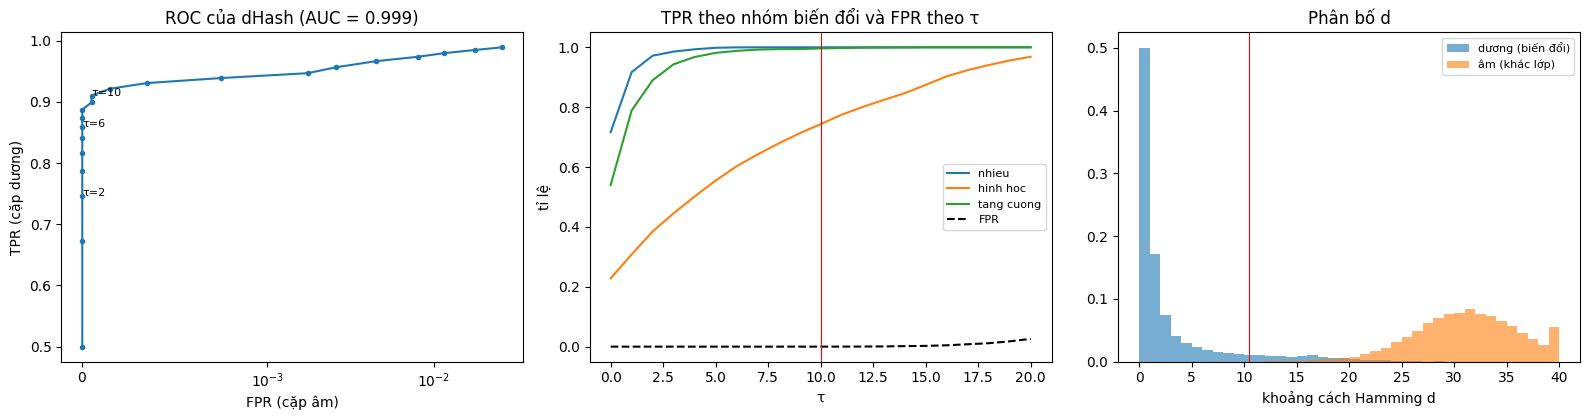

{
  "so_anh_thi_nghiem": 300,
  "so_phep_bien_doi": 26,
  "so_cap_duong": 7800,
  "so_cap_am": 20000,
  "AUC": 0.9987,
  "fpr_moc": 0.005,
  "tau_lon_nhat_FPR_duoi_moc": 16,
  "tau_chon": 10,
  "TPR_tai_tau_chon": 0.9101,
  "FPR_tai_tau_chon": 5e-05,
  "seed": 42
}
Gửi lại cho Claude: summary.json, tables/roc_theo_tau.csv, tables/theo_phep_bien_doi.csv, figures/roc_dhash.png


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
ax[0].plot(roc.FPR, roc.TPR, marker='o', ms=3)
for t in (2, 6, TAU_CHON):
    r = roc[roc.tau == t].iloc[0]; ax[0].annotate(f'τ={t}', (r.FPR, r.TPR), fontsize=8)
ax[0].set_xscale('symlog', linthresh=1e-3); ax[0].set_xlabel('FPR (cặp âm)'); ax[0].set_ylabel('TPR (cặp dương)')
ax[0].set_title(f'ROC của dHash (AUC = {auc:.3f})')
for g in pos.nhom.unique():
    ax[1].plot(roc.tau, roc[f'TPR_{g}'], label=g)
ax[1].plot(roc.tau, roc.FPR, 'k--', label='FPR')
ax[1].axvline(TAU_CHON, color='r', lw=0.8); ax[1].set_xlabel('τ'); ax[1].set_ylabel('tỉ lệ'); ax[1].legend(fontsize=8)
ax[1].set_title('TPR theo nhóm biến đổi và FPR theo τ')
bins = np.arange(0, 41)
ax[2].hist(pos.d.clip(upper=40), bins=bins, alpha=.6, density=True, label='dương (biến đổi)')
ax[2].hist(neg.d.clip(upper=40), bins=bins, alpha=.6, density=True, label='âm (khác lớp)')
ax[2].axvline(TAU_CHON + 0.5, color='r', lw=0.8); ax[2].set_xlabel('khoảng cách Hamming d'); ax[2].legend(fontsize=8)
ax[2].set_title('Phân bố d')
plt.tight_layout(); fig.savefig(FIG_DIR / 'roc_dhash.png', dpi=150); plt.show()

summary = {'so_anh_thi_nghiem': int(len(exp_idx)), 'so_phep_bien_doi': len(TRANSFORMS), 'so_cap_duong': int(len(pos)),
           'so_cap_am': int(len(neg)), 'AUC': round(auc, 4), 'fpr_moc': FPR_MOC, 'tau_lon_nhat_FPR_duoi_moc': tau_moc,
           'tau_chon': TAU_CHON, 'TPR_tai_tau_chon': round(float(r10.TPR), 4), 'FPR_tai_tau_chon': round(float(r10.FPR), 5),
           'seed': SEED}
json.dump(summary, open(OUT_DIR / 'summary.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
print(json.dumps(summary, ensure_ascii=False, indent=2))
print('Gửi lại cho Claude: summary.json, tables/roc_theo_tau.csv, tables/theo_phep_bien_doi.csv, figures/roc_dhash.png')